# Tăng cường ảnh thiếu sáng cho nhận diện biển báo

Bài tập lớn môn Xử lý ảnh - GTSRB, 43 lớp

Ảnh gốc → tạo ảnh tối → Gamma / HE / CLAHE / Retinex và ba enhancer pretrained → so sánh ảnh, histogram, PSNR/SSIM → kiểm chứng bằng ResNet
Train mới ba seed ResNet trên ảnh clean, rồi giữ cố định. Đánh giá mới dùng 430 ảnh test (10/lớp); đây là subset, không phải full-test 12.630 ảnh

## 1. Clone repo và cài môi trường
Chạy trên Kaggle, sử dụng 2 GPU T4.


In [1]:
import os, sys, subprocess
from pathlib import Path
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
ROOT = Path('/tmp/gtsrb-notebook')
REPO = 'https://github.com/ZesyC/low-light-enhancement-for-traffic-sign-recognition.git'
subprocess.run(['git', 'clone', '--quiet', REPO, str(ROOT)], check=True)
subprocess.run(['git', '-C', str(ROOT), 'checkout', '--quiet', '82a7c2e4732c6bd0c0808999703e799a026f17c0'], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
BUNDLE = next(Path('/kaggle/input').rglob('notebook_bundle.json')).parent
sys.path.insert(0, str(BUNDLE))
import notebook_helpers as nb
config, device, output = nb.setup(ROOT, BUNDLE)


Đã clone code dự án từ GitHub; không thay torch CUDA của Kaggle.
GPU: Tesla T4


In [2]:
from src.training import train
from src.experiment import tune, freeze, evaluate


## 2. Chuẩn bị dữ liệu
Dùng hàm chuẩn bị dữ liệu trong repo: chia train/validation theo track, crop ROI có padding 5% và resize RGB 64×64. Track chứa bản sao pixel của test được cách ly. Chọn ảnh minh họa từ validation và chốt subset test trước training.


Prepared 0/51839 crops
Prepared 10000/51839 crops
Prepared 20000/51839 crops
Prepared 30000/51839 crops
Prepared 40000/51839 crops
Prepared 50000/51839 crops


,Số ảnh
split,
quarantine,30
test,12630
train,31350
validation,7829


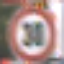

In [3]:
rows, test, examples, example, clean = nb.prepare_data(ROOT, config, BUNDLE)


## 3. Xử lý ảnh
Tạo ảnh tối: gamma > 1 làm giảm cường độ; Poisson mô phỏng nhiễu phụ thuộc tín hiệu; Gaussian bổ sung nhiễu cộng

Tăng sáng:
- Gamma: dùng số mũ < 1 để nâng vùng tối
- HE: cân bằng histogram độ sáng Y, giữ hai kênh màu
- CLAHE: cân bằng cục bộ; clipLimit hạn chế khuếch đại tương phản/nhiễu
- Multi-Scale Retinex: tách phản xạ và chiếu sáng ở nhiều thang Gaussian


,gamma_dark,poisson_peak,gaussian_sigma
mild,1.5,120.0,0.005
medium,2.2,60.0,0.010
severe,3.0,30.0,0.020


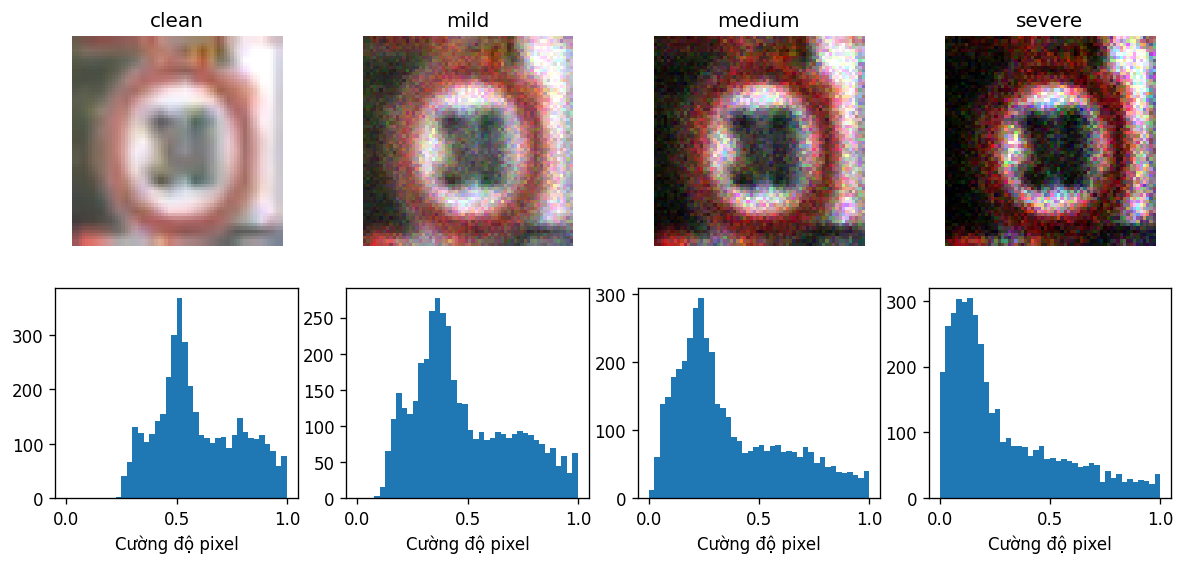

,Ảnh,psnr,ssim
0,clean,inf,1.0000
1,mild,17.2577,0.7120
2,medium,12.0942,0.5494
3,severe,9.5306,0.3855


In [4]:
dark = nb.show_degradation(clean, example, config)


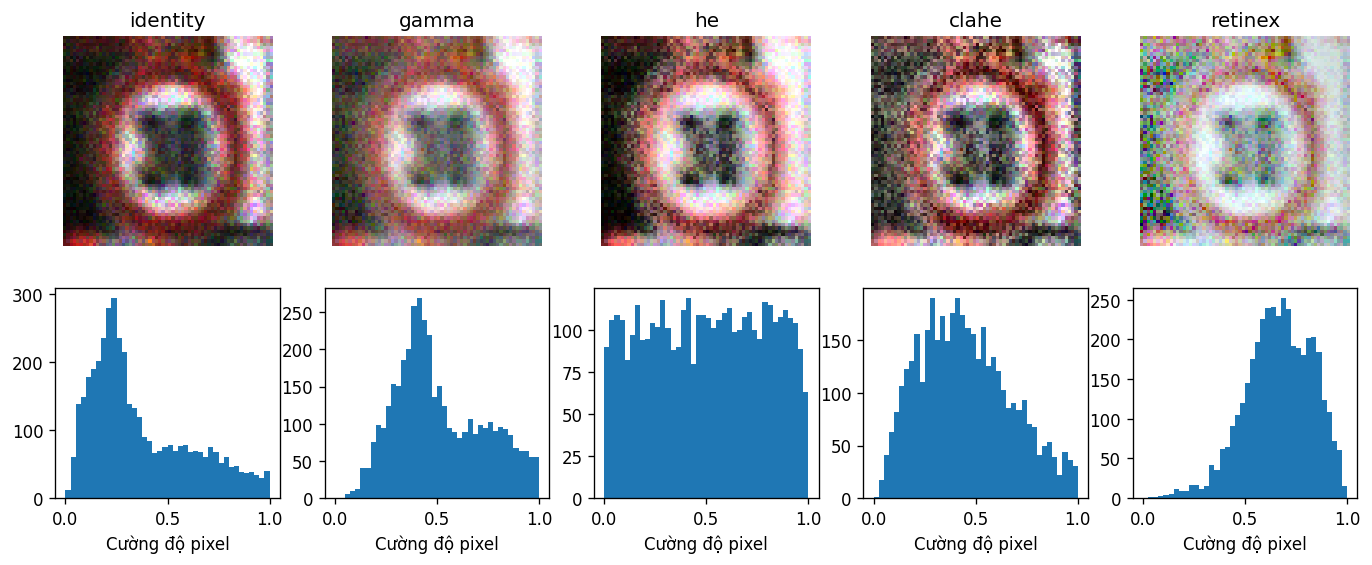

,Phương pháp,psnr,ssim
0,identity,12.0942,0.5494
1,gamma,19.0424,0.6743
2,he,15.9259,0.5834
3,clahe,13.5535,0.4777
4,retinex,16.1704,0.5694


In [5]:
nb.show_classical(clean, dark['medium'], config)


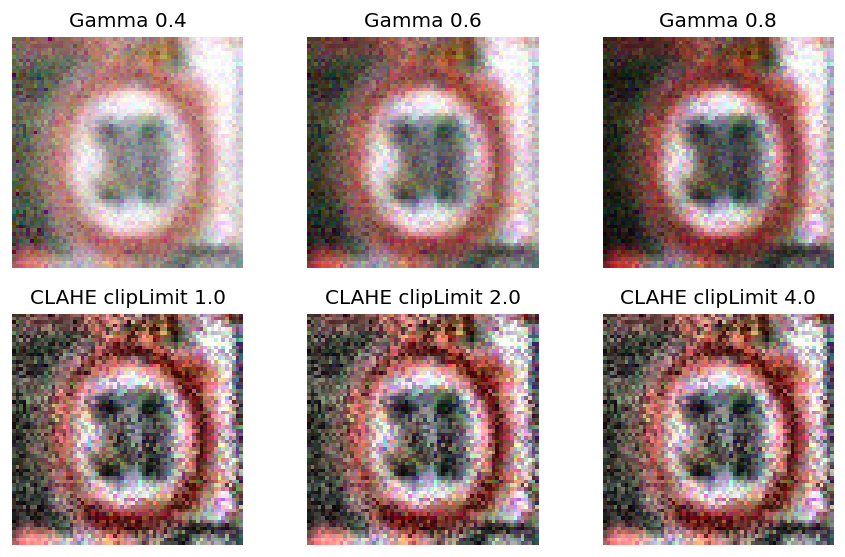

Gamma nhỏ nâng sáng mạnh hơn; CLAHE clipLimit lớn có thể làm nhiễu rõ hơn. Chọn tham số bằng validation.


In [6]:
nb.show_parameters(dark['medium'])


## 4. Train ResNet để kiểm chứng
- train mới ba seed 11/22/33 trên ảnh clean
- ResNet-18 khởi tạo ImageNet, AdamW, batch 32, tối đa 20 epoch và early stopping theo validation và không train ảnh tối/enhanced

In [7]:
checkpoints = [train(ROOT, config, seed, device, output/'train') for seed in [11,22,33]]
nb.show_training(output)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 122MB/s]


seed=11 epoch=1 val_loss=0.0387 macro_f1=0.9768
seed=11 epoch=2 val_loss=0.0403 macro_f1=0.9796
seed=11 epoch=3 val_loss=0.0304 macro_f1=0.9684
seed=11 epoch=4 val_loss=0.0373 macro_f1=0.9814
seed=11 epoch=5 val_loss=0.0643 macro_f1=0.9718
seed=11 epoch=6 val_loss=0.0356 macro_f1=0.9718
seed=11 epoch=7 val_loss=0.0766 macro_f1=0.9456
seed=11 epoch=8 val_loss=0.0193 macro_f1=0.9943
seed=11 epoch=9 val_loss=0.0265 macro_f1=0.9872
seed=11 epoch=10 val_loss=0.0276 macro_f1=0.9893
seed=11 epoch=11 val_loss=0.0198 macro_f1=0.9939
seed=11 epoch=12 val_loss=0.0095 macro_f1=0.9968
seed=11 epoch=13 val_loss=0.0259 macro_f1=0.9881
seed=11 epoch=14 val_loss=0.0201 macro_f1=0.9890
seed=11 epoch=15 val_loss=0.0103 macro_f1=0.9940
seed=11 epoch=16 val_loss=0.0207 macro_f1=0.9930
seed=11 epoch=17 val_loss=0.0550 macro_f1=0.9833
seed=11 early stop at epoch=17: patience=5, min_delta=0.001
seed=22 epoch=1 val_loss=0.0540 macro_f1=0.9710
seed=22 epoch=2 val_loss=0.0348 macro_f1=0.9662
seed=22 epoch=3 val_

,seed,accuracy,macro_f1,weighted_f1
0,11,0.9972,0.9968,0.9972
1,22,0.9967,0.9963,0.9967
2,33,0.9934,0.9911,0.9933


## 5. Chọn tham số trên validation
Dùng 1.290 ảnh validation để chọn Gamma, CLAHE, Retinex và pipeline; không chọn bằng test. Zero-DCE, Retinexformer và Diffusion dùng weights tác giả để tăng sáng, không train lại enhancer trên GTSRB.


In [8]:
selection = tune(ROOT, config, checkpoints, device, output/'validation', per_class=30)
nb.show_validation(selection)

validation identity {}: 0.67253
validation gamma {'gamma': 0.4}: 0.64457
validation gamma {'gamma': 0.6}: 0.67562
validation gamma {'gamma': 0.8}: 0.68678
validation he {}: 0.64524
validation clahe {'clip_limit': 1.0, 'tile_grid': [4, 4]}: 0.71819
validation clahe {'clip_limit': 1.0, 'tile_grid': [8, 8]}: 0.65963
validation clahe {'clip_limit': 2.0, 'tile_grid': [4, 4]}: 0.72018
validation clahe {'clip_limit': 2.0, 'tile_grid': [8, 8]}: 0.65963
validation clahe {'clip_limit': 4.0, 'tile_grid': [4, 4]}: 0.70779
validation clahe {'clip_limit': 4.0, 'tile_grid': [8, 8]}: 0.65963
validation retinex {'sigmas': [3, 10, 20]}: 0.45350
validation retinex {'sigmas': [5, 15, 30]}: 0.47307
validation zero_dce {'repo': 'external/Zero-DCE', 'checkpoint': 'external/Zero-DCE/Zero-DCE_code/snapshots/Epoch99.pth', 'pretraining': 'SICE subset; see author README'}: 0.61472
validation retinexformer {'repo': 'external/Retinexformer', 'checkpoint': 'external/Retinexformer/pretrained_weights/LOL_v1.pth', 'con

,method,params,macro_f1,latency_ms
0,identity,{},0.672526,0.120914
1,gamma,{'gamma': 0.8},0.686784,0.213963
2,he,{},0.645238,0.197702
3,clahe,"{'clip_limit': 2.0, 'tile_grid': [4, 4]}",0.720179,0.406062
4,retinex,"{'sigmas': [5, 15, 30]}",0.473071,2.109547
5,zero_dce,"{'repo': 'external/Zero-DCE', 'checkpoint': 'e...",0.614724,1.803798
6,retinexformer,"{'repo': 'external/Retinexformer', 'checkpoint...",0.653610,12.106447
7,diffusion,"{'repo': 'external/Diffusion-Low-Light', 'chec...",0.759636,225.425822


Pipeline chọn trên validation: diffusion


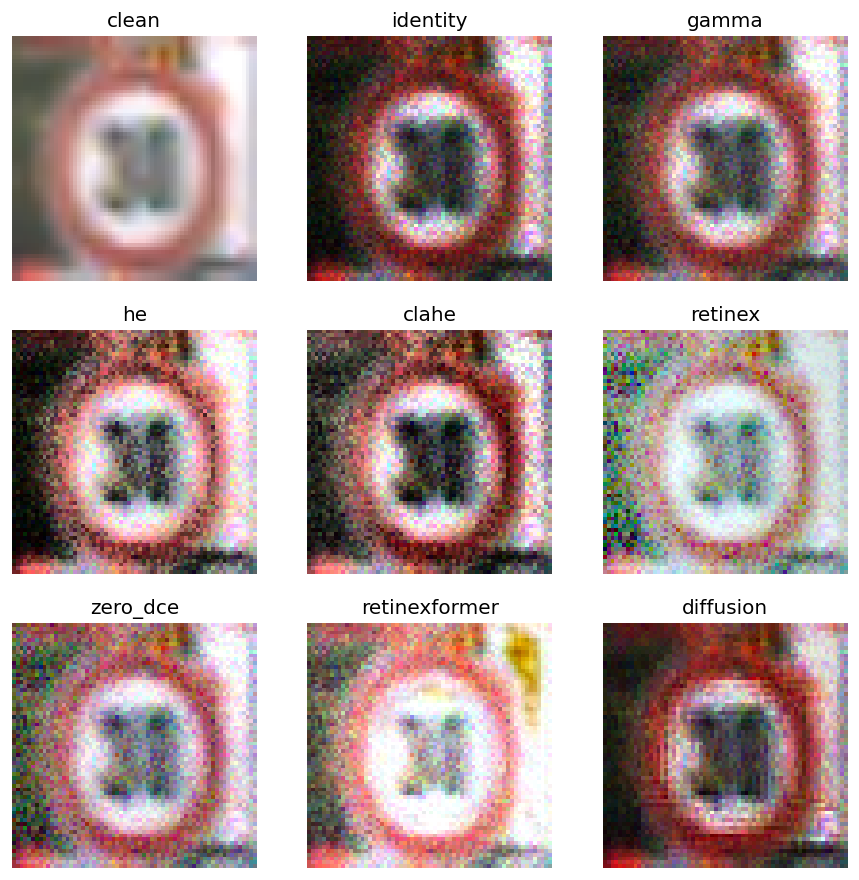

,method,psnr,ssim
0,identity,12.0942,0.5494
1,gamma,14.5302,0.6168
2,he,15.9259,0.5834
3,clahe,13.7357,0.5521
4,retinex,17.2342,0.6058
5,zero_dce,20.2418,0.6181
6,retinexformer,14.4360,0.4843
7,diffusion,12.2673,0.5885


In [9]:
nb.show_enhancers(clean, dark['medium'], example, selection, device, config)

## 6. Đánh giá và đọc kết quả
- PSNR/SSIM: mức giữ lại thông tin ảnh. 
- Macro-F1: kiểm chứng khả năng nhận diện đủ 43 lớp. So với identity để thấy tăng sáng giúp hay làm hỏng nhận diện. Mean ± SD được tính qua ba training seed sau khi trung bình noise trong mỗi seed.

In [10]:
protocol = freeze(ROOT, output/'validation/selection.json', output/'protocol_subset.json', per_class=10)
evaluate(ROOT, output/'protocol_subset.json', output/'test_subset', device)

1/219 {'condition': 'clean', 'noise_seed': '', 'method': 'clean', 'train_seed': 11}: macro_f1=0.9929
2/219 {'condition': 'mild', 'noise_seed': 101, 'method': 'identity', 'train_seed': 11}: macro_f1=0.9299
3/219 {'condition': 'mild', 'noise_seed': 101, 'method': 'gamma', 'train_seed': 11}: macro_f1=0.9362
4/219 {'condition': 'mild', 'noise_seed': 101, 'method': 'he', 'train_seed': 11}: macro_f1=0.9335
5/219 {'condition': 'mild', 'noise_seed': 101, 'method': 'clahe', 'train_seed': 11}: macro_f1=0.9261
6/219 {'condition': 'mild', 'noise_seed': 101, 'method': 'retinex', 'train_seed': 11}: macro_f1=0.8544
7/219 {'condition': 'mild', 'noise_seed': 101, 'method': 'zero_dce', 'train_seed': 11}: macro_f1=0.9289
8/219 {'condition': 'mild', 'noise_seed': 101, 'method': 'retinexformer', 'train_seed': 11}: macro_f1=0.8021
9/219 {'condition': 'mild', 'noise_seed': 101, 'method': 'diffusion', 'train_seed': 11}: macro_f1=0.9411
10/219 {'condition': 'medium', 'noise_seed': 101, 'method': 'identity', 't

[{'dataset': 'gtsrb',
  'split': 'test',
  'protocol': 'A',
  'subset_id': 'cdc811f2b9c31008',
  'condition': 'clean',
  'noise_seed': '',
  'method': 'clean',
  'train_seed': 11,
  'run_id': '5722834c25a0be18',
  'config_id': '44136fa355b3678a',
  'n_images': 430,
  'accuracy': 0.9930232558139535,
  'macro_f1': 0.992875599852344,
  'weighted_f1': 0.9928755998523441,
  'psnr_mean': inf,
  'ssim_mean': 1.0,
  'latency_ms': 0.0},
 {'dataset': 'gtsrb',
  'split': 'test',
  'protocol': 'A',
  'subset_id': 'cdc811f2b9c31008',
  'condition': 'mild',
  'noise_seed': 101,
  'method': 'identity',
  'train_seed': 11,
  'run_id': 'c0b2c52580ddf4d2',
  'config_id': '44136fa355b3678a',
  'n_images': 430,
  'accuracy': 0.9302325581395349,
  'macro_f1': 0.9298897511043912,
  'weighted_f1': 0.9298897511043915,
  'psnr_mean': 19.487589224641987,
  'ssim_mean': 0.6076888939668966,
  'latency_ms': 0.12347141626716705},
 {'dataset': 'gtsrb',
  'split': 'test',
  'protocol': 'A',
  'subset_id': 'cdc811f2b9

{
  "status": "verified",
  "runs": 219,
  "images_per_run": 430,
  "predictions_checked": 94170,
  "manifest_sha256": "97f2c9ba1d9a16b1e37c10739ad6cff47d3c92ab813fb982e47daaeab01343c0",
  "protocol_sha256": "166fcb4804bf60018c15d3a2e60757d4cb38b7b9050efe95f605c1636669de48",
  "checks": [
    "checkpoint hashes",
    "test labels and exact ID coverage",
    "Accuracy/Macro-F1/Weighted-F1 recomputed",
    "mean and SD across training seeds"
  ]
}


,condition,method,accuracy (%),macro_f1 (%),PSNR,SSIM
0,clean,clean,98.53 ± 0.82,98.50 ± 0.83,inf,1.0000
1,medium,clahe,78.50 ± 1.13,80.14 ± 1.97,19.29,0.5568
2,medium,diffusion,82.95 ± 3.16,82.71 ± 3.08,14.90,0.5410
3,medium,gamma,74.83 ± 2.87,76.81 ± 2.83,17.18,0.4498
4,medium,he,72.48 ± 6.33,75.25 ± 5.53,11.36,0.3237
5,medium,identity,73.05 ± 2.54,75.35 ± 2.55,15.37,0.3410
6,medium,retinex,48.06 ± 4.03,50.97 ± 4.09,6.60,0.2409
7,medium,retinexformer,72.89 ± 3.82,73.63 ± 3.74,14.78,0.4780
8,medium,zero_dce,66.02 ± 5.40,69.30 ± 4.22,20.08,0.4509
9,mild,clahe,91.94 ± 1.17,91.98 ± 1.30,21.61,0.6369


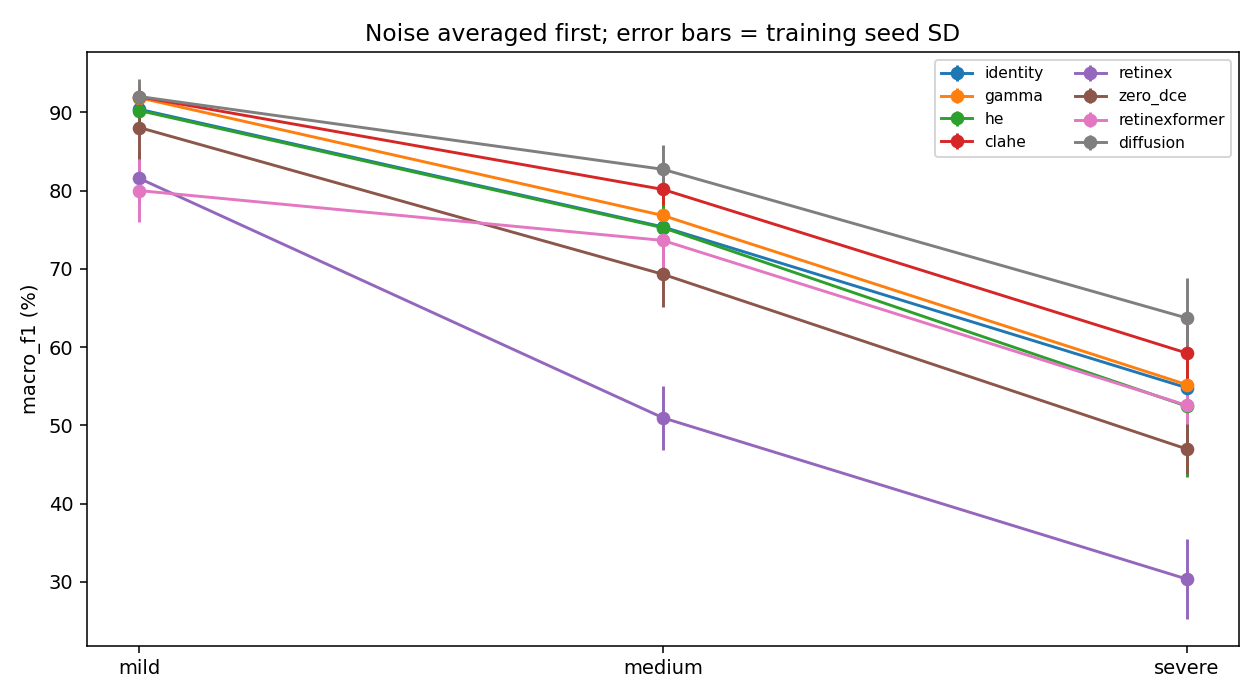

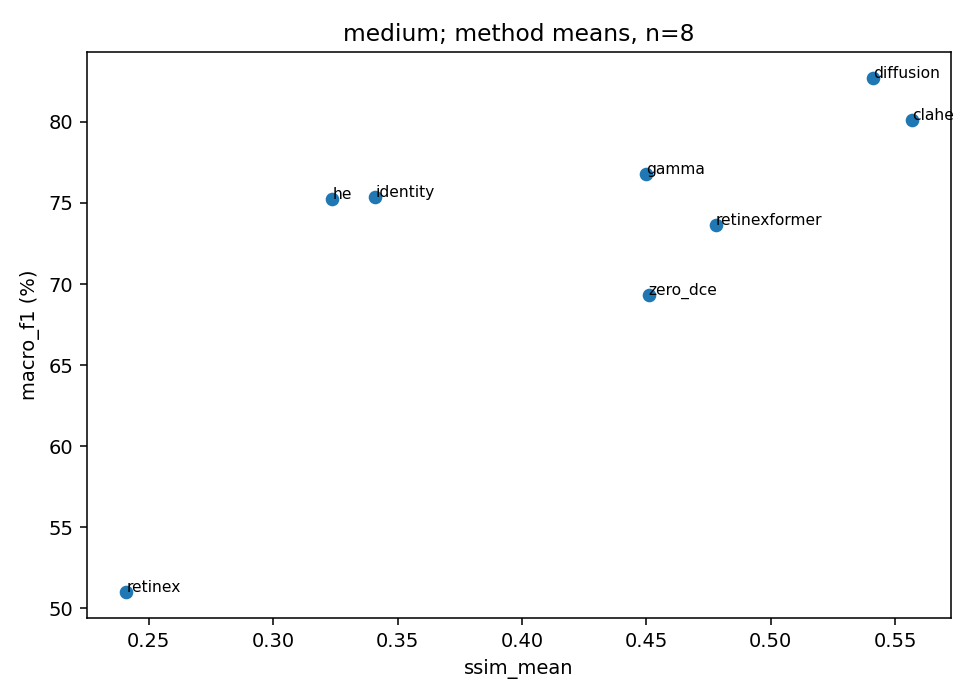

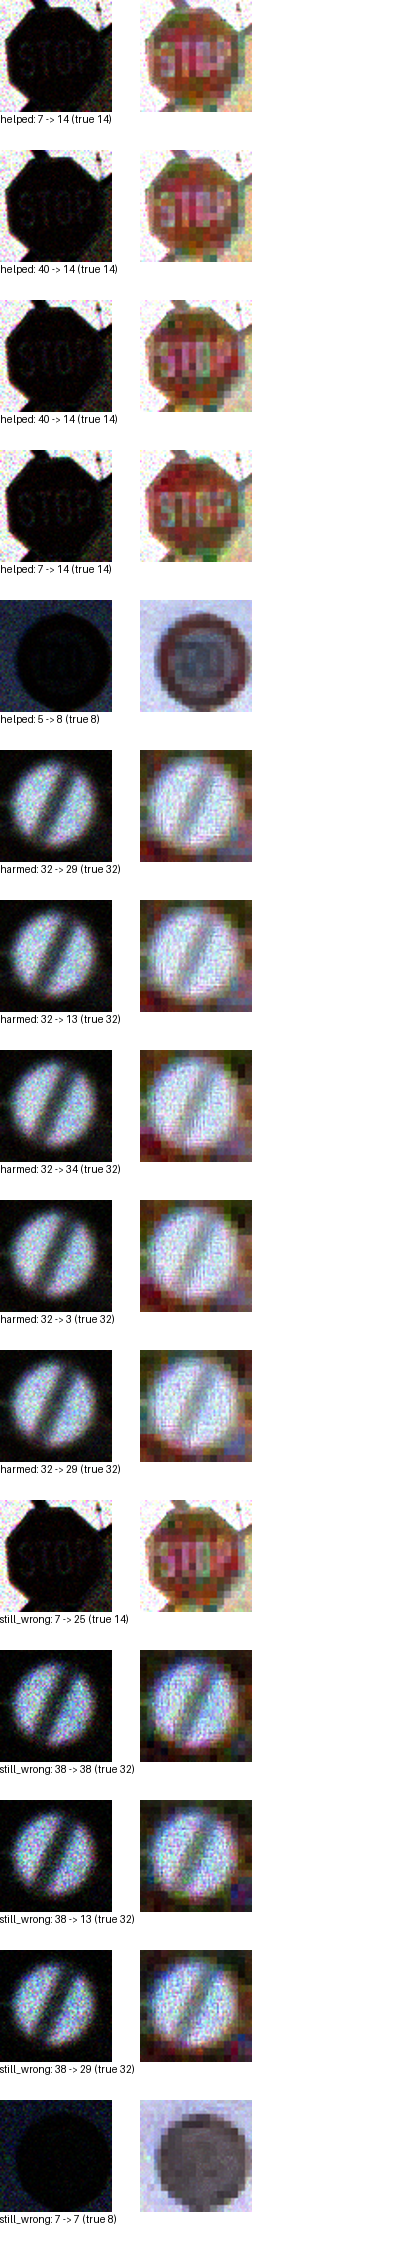

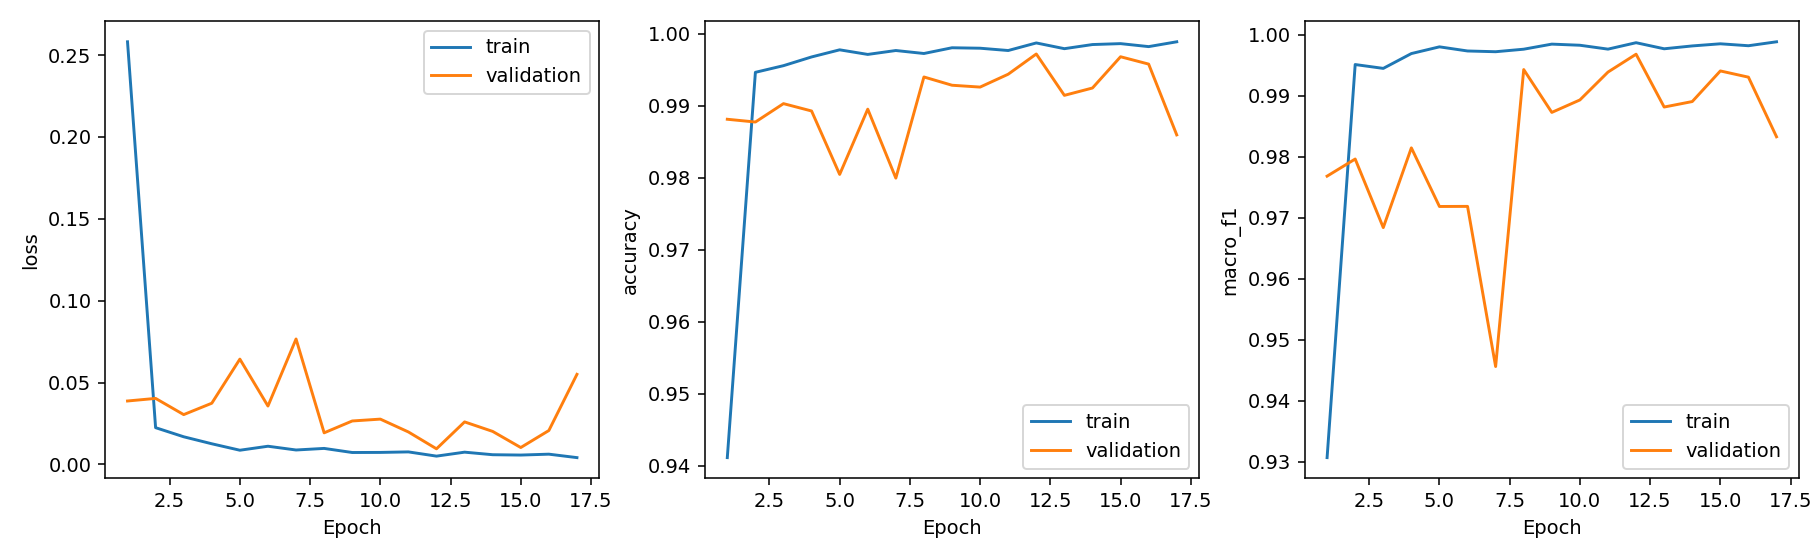

Xem trường hợp được giúp/sai thêm: ảnh sáng hơn chưa chắc giữ tốt chi tiết để nhận diện.


In [11]:
nb.show_results(ROOT, output)

## 7. Ablation, demo và xuất kết quả
Tách gamma-only / gamma + Gaussian / gamma + Poisson / gamma + cả hai để giải thích tác động của từng bước xử lý ảnh. Giữ nguyên classifier và tham số đã chọn: 288 lượt trên cùng 430 ảnh. Khi tắt Poisson, chuỗi RNG Gaussian cũng thay đổi; gamma-only không tạo ba ảnh độc lập.

Demo dùng một ảnh validation cố định mỗi lớp. Các cell phụ dưới đây chỉ gọi lại hàm xử lý ảnh và dự đoán từ repo. Kết luận giới hạn ở thiếu sáng mô phỏng sRGB, không suy ra hiệu quả camera đêm thực tế.

In [12]:
nb.run_ablation(ROOT, config, selection, checkpoints, device, test)

3/288: gamma_only, noise 101, identity
6/288: gamma_only, noise 101, gamma
9/288: gamma_only, noise 101, he
12/288: gamma_only, noise 101, clahe
15/288: gamma_only, noise 101, retinex
18/288: gamma_only, noise 101, zero_dce
21/288: gamma_only, noise 101, retinexformer
24/288: gamma_only, noise 101, diffusion
27/288: gamma_only, noise 202, identity
30/288: gamma_only, noise 202, gamma
33/288: gamma_only, noise 202, he
36/288: gamma_only, noise 202, clahe
39/288: gamma_only, noise 202, retinex
42/288: gamma_only, noise 202, zero_dce
45/288: gamma_only, noise 202, retinexformer
48/288: gamma_only, noise 202, diffusion
51/288: gamma_only, noise 303, identity
54/288: gamma_only, noise 303, gamma
57/288: gamma_only, noise 303, he
60/288: gamma_only, noise 303, clahe
63/288: gamma_only, noise 303, retinex
66/288: gamma_only, noise 303, zero_dce
69/288: gamma_only, noise 303, retinexformer
72/288: gamma_only, noise 303, diffusion
75/288: gamma_gaussian, noise 101, identity
78/288: gamma_gaussi

VERIFIED: /tmp/gtsrb-notebook/outputs/research_evidence/verification.json
DEMO: /tmp/gtsrb-notebook/outputs/research_evidence/demo/index.html


,variant,method,macro_f1_mean,macro_f1_std
0,gamma_both,clahe,0.8014,0.0197
1,gamma_both,diffusion,0.8271,0.0308
2,gamma_both,gamma,0.7681,0.0283
3,gamma_both,he,0.7525,0.0553
4,gamma_both,identity,0.7535,0.0255
5,gamma_both,retinex,0.5097,0.0409
6,gamma_both,retinexformer,0.7363,0.0374
7,gamma_both,zero_dce,0.6930,0.0422
8,gamma_gaussian,clahe,0.8820,0.0132
9,gamma_gaussian,diffusion,0.9069,0.0092


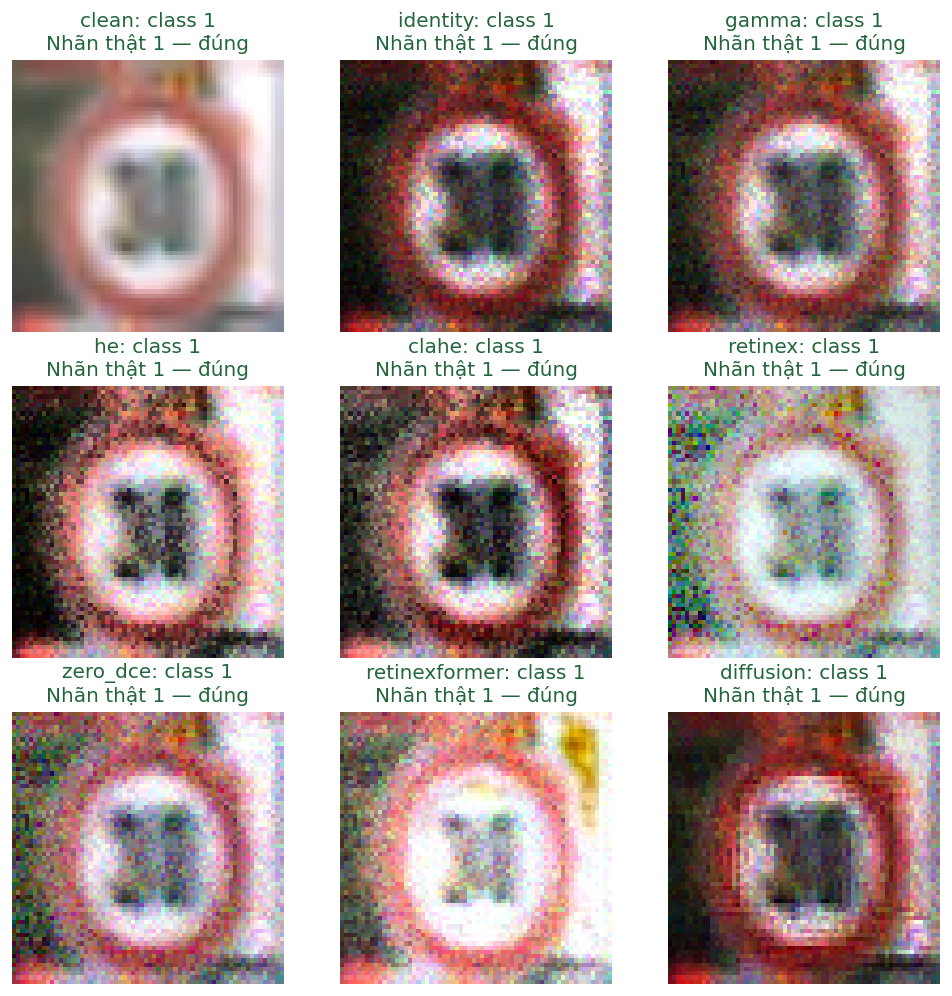

In [13]:
nb.run_demo(ROOT, config, selection, checkpoints, device, examples)

In [14]:
nb.export_results(ROOT, output, selection, checkpoints)

Pipeline chọn bằng validation: diffusion
mild: thay đổi Macro-F1 so ảnh tối +1.63 điểm phần trăm
medium: thay đổi Macro-F1 so ảnh tối +7.36 điểm phần trăm
severe: thay đổi Macro-F1 so ảnh tối +8.91 điểm phần trăm
/tmp/gtsrb-notebook/outputs/notebook_A/test_subset/discussion.md
/tmp/gtsrb-notebook/outputs/notebook_A/test_subset/slides.html
COMPLETE: /kaggle/working/gtsrb-notebook-results.zip


'/kaggle/working/gtsrb-notebook-results.zip'